In [1]:
%matplotlib inline
import torch
import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Define which device to use for computations
# If you have gpu, use 'cuda'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("You train on {}".format(device))

You train on cuda


## Prepare data for training and testing

In [5]:
# Local Storage
transform =  transforms.Compose([transforms.Grayscale(), transforms.ToTensor()])
mnist_train = torchvision.datasets.ImageFolder(root="mnist-png-format/train", transform=transform)
mnist_test = torchvision.datasets.ImageFolder(root="mnist-png-format/test", transform=transform)

print("Size of MNIST Training Set =" ,len(mnist_train))
print("Size of MNIST Testing Set =" ,len(mnist_test))

Size of MNIST Training Set = 60000
Size of MNIST Testing Set = 10000


## Design training settings

In [6]:
# Defining Data Loaders with batch size 64

from torch.utils.data import DataLoader

train_loader = DataLoader(mnist_train, batch_size=64, shuffle=True)
test_loader = DataLoader(mnist_test, batch_size=64, shuffle=True)

### Model Setup

In [7]:
import torch.nn as nn

# Multilayer Perceptron Model with one hidden layer and ReLU activation function:
class MLP_Model(nn.Module):
    
    def __init__(self, input_dim, hidden_dim):
        super(MLP_Model, self).__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 10)
        )
    
    def forward(self, input):
        input = input.view(input.size(0), -1)
        return self.layers(input)   

In [8]:
input_dim = 28*28
hidden_dim = 100  #Number of neurons in the hidden layer
learning_rate = 0.1

model = MLP_Model(input_dim, hidden_dim)
model = model.to(device)
optimizer = torch.optim.SGD(model.parameters(), lr = learning_rate)
loss_fn = nn.CrossEntropyLoss()

In [9]:
# Training loop in each epoch on training set
def train_epoch(model, train_dataloader, optimizer, loss_fn):
    losses = []
    correct_predictions = 0
    
    # Iterate mini batches over training dataset
    for images, labels in train_dataloader:
        images = images.to(device)
        labels = labels.to(device)
        
        # Run predictions
        output = model(images)
        
        # Set gradients to zero
        optimizer.zero_grad()
        
        # Compute loss
        loss = loss_fn(output, labels)
        
        # Backpropagate (compute gradients)
        loss.backward()
        
        # Make an optimization step (update parameters)
        optimizer.step()
        
        # Log metrics
        losses.append(loss.item())
        predicted_labels = output.argmax(dim=1)
        correct_predictions += (predicted_labels == labels).sum().item()
        
    # Return mean loss value and accuracy for each iteration
    mean_loss = np.array(losses).mean()
    model_accuracy = 100.0 * correct_predictions / len(train_dataloader.dataset)
    
    return mean_loss, model_accuracy

# Evaluation loop in each epoch on testing set
def evaluate_epoch(model, eval_dataloader, loss_fn):
    losses = []
    correct_predictions = 0
    
    with torch.no_grad():
        for images, labels in eval_dataloader:
            images = images.to(device)
            labels = labels.to(device)
            
            # Run predictions
            output = model(images)
            
            # Compute loss
            loss = loss_fn(output, labels)
            
            # Log metrics
            losses.append(loss.item())
            predicted_labels = output.argmax(dim=1)
            correct_predictions += (predicted_labels == labels).sum().item()
            
            
    # Return mean loss value and accuracy for each iteration
    mean_loss = np.array(losses).mean()
    model_accuracy = 100.0 * correct_predictions / len(eval_dataloader.dataset)
    
    return mean_loss, model_accuracy

# Training and Performing validation
def train(model, train_dataloader, val_dataloader, optimizer, n_epochs, loss_function):
    # We will monitor loss functions as the training progresses
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    for epoch in range(n_epochs):
        model.train()
        train_loss, train_accuracy = train_epoch(model, train_dataloader, optimizer, loss_fn)
        model.eval()
        val_loss, val_accuracy = evaluate_epoch(model, val_dataloader, loss_fn)
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(train_accuracy)
        val_accuracies.append(val_accuracy)
        print('Epoch {}/{}: train_loss: {:.4f}, train_accuracy: {:.4f}, val_loss: {:.4f}, val_accuracy: {:.4f}'.format(epoch+1, n_epochs,
                                                                                                      train_losses[-1],
                                                                                                      train_accuracies[-1],
                                                                                                      val_losses[-1],
                                                                                                      val_accuracies[-1]))
    return train_losses, train_accuracies, val_losses, val_accuracies

### Plotting Function

In [10]:
def plot_L_A(train_losses, val_losses, train_accuracies, val_accuracies):
    plt.subplots(figsize=(15,5))
    plt.suptitle('Training and validation loss and accuracy')
    plt.subplot(121)
    plt.plot(np.arange(len(train_losses)), train_losses)
    plt.plot(np.arange(len(val_losses)), val_losses)
    plt.legend(['Train_Loss', 'Val_Loss'])
    plt.xlabel('Epoch')
    plt.ylabel('Loss Value')
    plt.title('Train & Val Loss')

    plt.subplot(122)
    plt.plot(np.arange(len(train_accuracies)), train_accuracies)
    plt.plot(np.arange(len(val_accuracies)), val_accuracies)
    plt.legend(['Train_Acc', 'Val_Acc'])
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title('Train & Val Accuracy')

### Train the model and report the results

#### Optimizing number of neurons in the hidden layer

Number of neurons in the hidden layer: 10
Epoch 1/20: train_loss: 0.5050, train_accuracy: 85.4533, val_loss: 0.3157, val_accuracy: 90.7000
Epoch 2/20: train_loss: 0.3020, train_accuracy: 91.2683, val_loss: 0.3016, val_accuracy: 91.4400
Epoch 3/20: train_loss: 0.2793, train_accuracy: 91.9367, val_loss: 0.2569, val_accuracy: 92.5300
Epoch 4/20: train_loss: 0.2641, train_accuracy: 92.4083, val_loss: 0.2512, val_accuracy: 93.0800
Epoch 5/20: train_loss: 0.2519, train_accuracy: 92.7283, val_loss: 0.2423, val_accuracy: 93.0300
Epoch 6/20: train_loss: 0.2422, train_accuracy: 93.0067, val_loss: 0.2318, val_accuracy: 93.5800
Epoch 7/20: train_loss: 0.2329, train_accuracy: 93.3217, val_loss: 0.2250, val_accuracy: 93.6600
Epoch 8/20: train_loss: 0.2261, train_accuracy: 93.5550, val_loss: 0.2314, val_accuracy: 93.5800
Epoch 9/20: train_loss: 0.2188, train_accuracy: 93.7550, val_loss: 0.2261, val_accuracy: 93.7100
Epoch 10/20: train_loss: 0.2147, train_accuracy: 93.9167, val_loss: 0.2427, val_accur

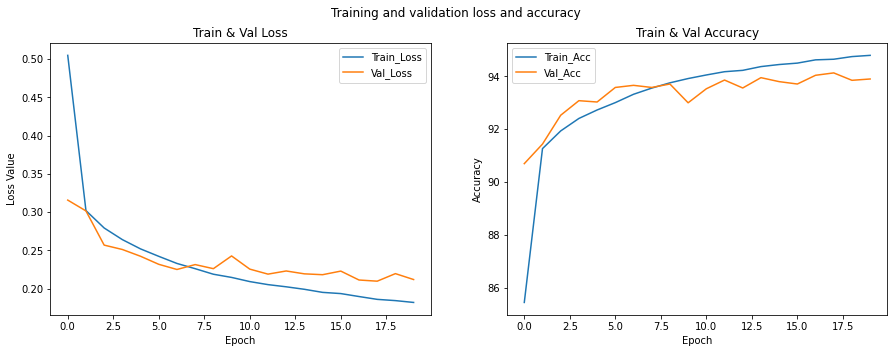

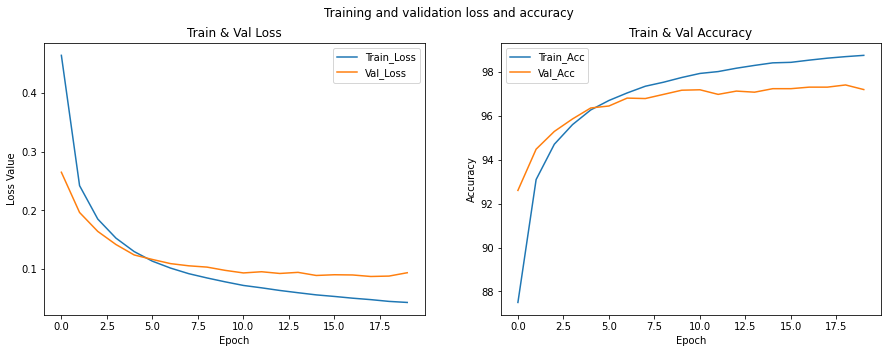

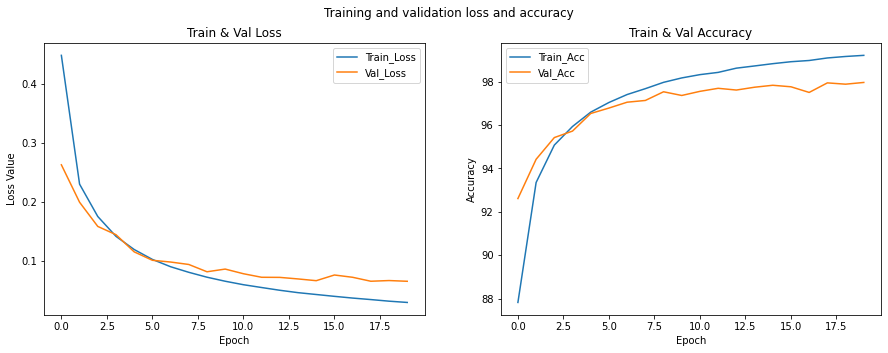

In [11]:
n_epochs = 20
hidden_dim_t = [10,50,100]  #Number of neurons in the hidden layer
learning_rate = 0.1

val_acc_list = []
train_acc_list = []

for i in range (3):
    model_t = MLP_Model(input_dim, hidden_dim_t[i])
    model_t = model_t.to(device)
    optimizer = torch.optim.SGD(model_t.parameters(), lr = learning_rate)
    loss_fn = nn.CrossEntropyLoss()
    print("Number of neurons in the hidden layer:", hidden_dim_t[i])
    train_losses_t, train_accuracies_t, val_losses_t, val_accuracies_t = train (model_t, train_loader, test_loader, optimizer, n_epochs, loss_fn)
    val_acc_list.append(val_accuracies_t[-1])
    train_acc_list.append(train_accuracies_t[-1])
    plot_L_A(train_losses_t, val_losses_t, train_accuracies_t, val_accuracies_t)

In [12]:
result1 = {'Hidden Layer Neurons No.': hidden_dim_t,'Training Accuracy': train_acc_list, 'Validation Accuracy': val_acc_list}
table1 = pd.DataFrame(result1)
table1

,Hidden Layer Neurons No.,Training Accuracy,Validation Accuracy
0,10,94.793333,93.90
1,50,98.770000,97.21
2,100,99.208333,97.96


In [13]:
hidden_dim_opt = hidden_dim_t[np.argmax(val_acc_list)]
print("The optimum number of neurons in the hidden layer is:", hidden_dim_opt)

The optimum number of neurons in the hidden layer is: 100


#### Optimizing Learning Rate

Learning Rate: 0.001
Epoch 1/20: train_loss: 2.2216, train_accuracy: 35.9350, val_loss: 2.1266, val_accuracy: 54.7700
Epoch 2/20: train_loss: 2.0155, train_accuracy: 62.3283, val_loss: 1.8776, val_accuracy: 69.0100
Epoch 3/20: train_loss: 1.7369, train_accuracy: 72.2333, val_loss: 1.5702, val_accuracy: 74.6900
Epoch 4/20: train_loss: 1.4360, train_accuracy: 76.0833, val_loss: 1.2791, val_accuracy: 78.5400
Epoch 5/20: train_loss: 1.1792, train_accuracy: 79.1017, val_loss: 1.0542, val_accuracy: 80.7400
Epoch 6/20: train_loss: 0.9895, train_accuracy: 81.1200, val_loss: 0.8950, val_accuracy: 82.5200
Epoch 7/20: train_loss: 0.8560, train_accuracy: 82.5350, val_loss: 0.7836, val_accuracy: 83.9700
Epoch 8/20: train_loss: 0.7611, train_accuracy: 83.6600, val_loss: 0.7030, val_accuracy: 85.1000
Epoch 9/20: train_loss: 0.6915, train_accuracy: 84.5550, val_loss: 0.6419, val_accuracy: 85.9500
Epoch 10/20: train_loss: 0.6385, train_accuracy: 85.2383, val_loss: 0.5976, val_accuracy: 86.5900
Epoch 11

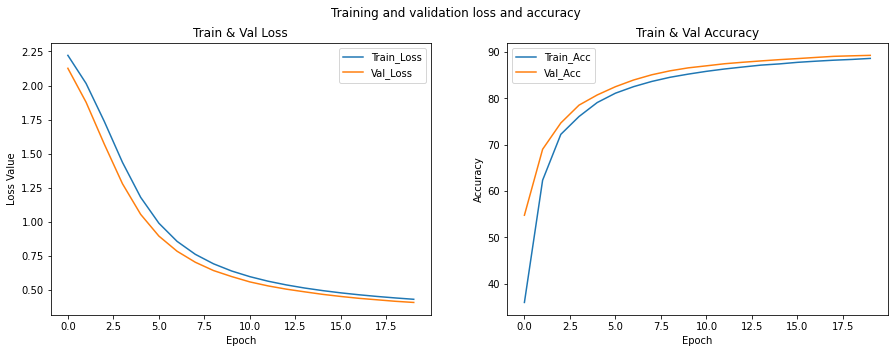

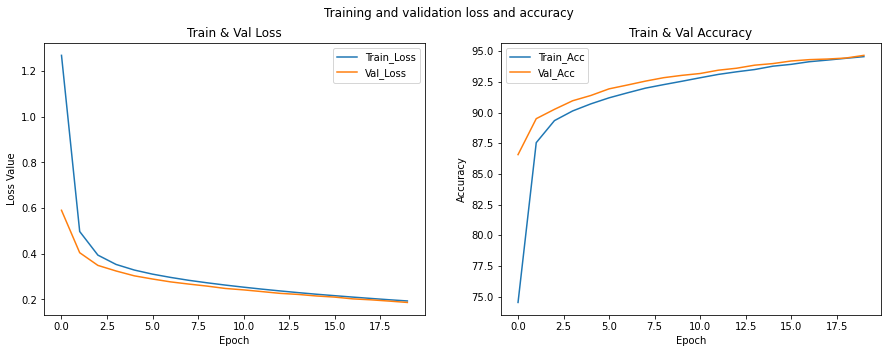

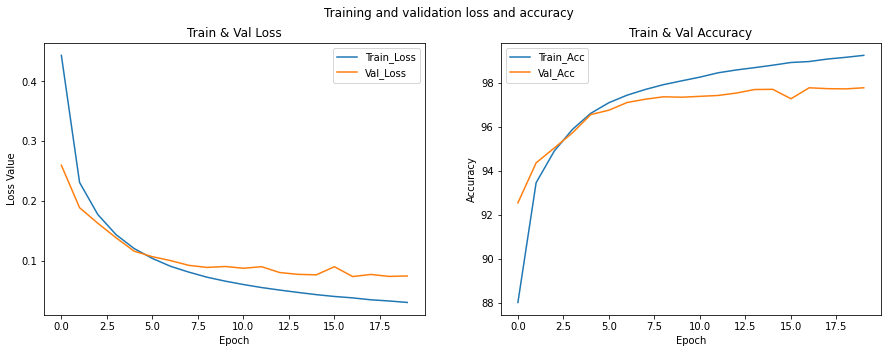

In [14]:
n_epochs = 20
learning_rate_t = [0.001,0.01,0.1] #Learning Rate

val_acc_list = []
train_acc_list = []

for i in range (3):
    model_t = MLP_Model(input_dim, hidden_dim_opt)
    model_t = model_t.to(device)
    optimizer = torch.optim.SGD(model_t.parameters(), lr = learning_rate_t[i])
    loss_fn = nn.CrossEntropyLoss()
    print("Learning Rate:", learning_rate_t[i])
    train_losses_t, train_accuracies_t, val_losses_t, val_accuracies_t = train (model_t, train_loader, test_loader, optimizer, n_epochs, loss_fn)
    val_acc_list.append(val_accuracies_t[-1])
    train_acc_list.append(train_accuracies_t[-1])
    plot_L_A(train_losses_t, val_losses_t, train_accuracies_t, val_accuracies_t)

In [15]:
result2 = {'Learning Rate': learning_rate_t,'Training Accuracy': train_acc_list, 'Validation Accuracy': val_acc_list}
table2 = pd.DataFrame(result2)
table2

,Learning Rate,Training Accuracy,Validation Accuracy
0,0.001,88.631667,89.29
1,0.010,94.555000,94.66
2,0.100,99.266667,97.79


In [16]:
learning_rate_opt = learning_rate_t[np.argmax(val_acc_list)]
print("The optimum Learning Rate is:", learning_rate_opt)

The optimum Learning Rate is: 0.1


#### Optimizing number of training iterations(Epochs)

In [17]:
n_epochs = 50

model_t = MLP_Model(input_dim, hidden_dim_opt)
model_t = model_t.to(device)
optimizer = torch.optim.SGD(model_t.parameters(), lr = learning_rate_opt)
loss_fn = nn.CrossEntropyLoss()

train_losses_t, train_accuracies_t, val_losses_t, val_accuracies_t = train (model_t, train_loader, test_loader, optimizer, n_epochs, loss_fn)

Epoch 1/50: train_loss: 0.4401, train_accuracy: 88.1700, val_loss: 0.2584, val_accuracy: 92.6600
Epoch 2/50: train_loss: 0.2281, train_accuracy: 93.5100, val_loss: 0.1831, val_accuracy: 94.6500
Epoch 3/50: train_loss: 0.1698, train_accuracy: 95.1867, val_loss: 0.1508, val_accuracy: 95.5400
Epoch 4/50: train_loss: 0.1352, train_accuracy: 96.1250, val_loss: 0.1290, val_accuracy: 96.2300
Epoch 5/50: train_loss: 0.1133, train_accuracy: 96.7633, val_loss: 0.1120, val_accuracy: 96.7200
Epoch 6/50: train_loss: 0.0978, train_accuracy: 97.2617, val_loss: 0.0991, val_accuracy: 97.0600
Epoch 7/50: train_loss: 0.0861, train_accuracy: 97.5683, val_loss: 0.0915, val_accuracy: 97.2200
Epoch 8/50: train_loss: 0.0763, train_accuracy: 97.7917, val_loss: 0.0906, val_accuracy: 97.2700
Epoch 9/50: train_loss: 0.0686, train_accuracy: 98.0617, val_loss: 0.0845, val_accuracy: 97.4300
Epoch 10/50: train_loss: 0.0623, train_accuracy: 98.1933, val_loss: 0.0834, val_accuracy: 97.6200
Epoch 11/50: train_loss: 0.05

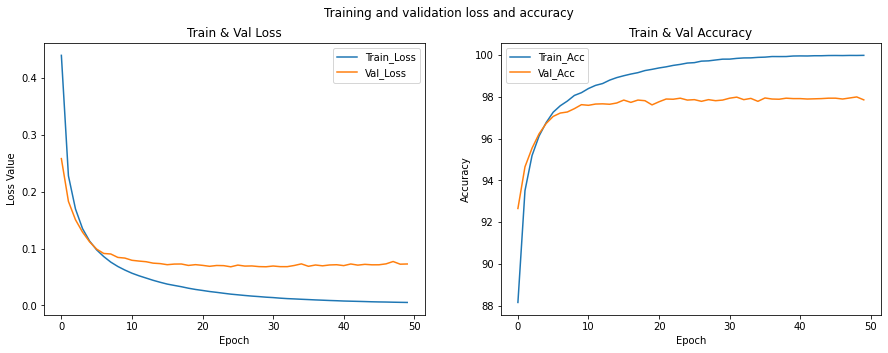

In [18]:
plot_L_A(train_losses_t, val_losses_t, train_accuracies_t, val_accuracies_t)

#### According to the above plots, we can approximately consider the optimum Epoch number = 15

### Training and Testing based on the best parameters

In [19]:
n_epochs_opt = 15 

model_opt = MLP_Model(input_dim, hidden_dim_opt)
model_opt = model_opt.to(device)
optimizer = torch.optim.SGD(model_opt.parameters(), lr = learning_rate_opt)
loss_fn = nn.CrossEntropyLoss()

train_losses_opt, train_accuracies_opt, val_losses_opt, val_accuracies_opt = train (model_opt, train_loader, test_loader, optimizer, n_epochs_opt, loss_fn)

Epoch 1/15: train_loss: 0.4450, train_accuracy: 88.0883, val_loss: 0.2567, val_accuracy: 92.4400
Epoch 2/15: train_loss: 0.2298, train_accuracy: 93.4100, val_loss: 0.2040, val_accuracy: 93.7500
Epoch 3/15: train_loss: 0.1739, train_accuracy: 95.0383, val_loss: 0.1618, val_accuracy: 95.2500
Epoch 4/15: train_loss: 0.1397, train_accuracy: 96.0417, val_loss: 0.1295, val_accuracy: 96.0900
Epoch 5/15: train_loss: 0.1168, train_accuracy: 96.6517, val_loss: 0.1128, val_accuracy: 96.7500
Epoch 6/15: train_loss: 0.1008, train_accuracy: 97.1633, val_loss: 0.1111, val_accuracy: 96.7300
Epoch 7/15: train_loss: 0.0883, train_accuracy: 97.4683, val_loss: 0.0934, val_accuracy: 97.1400
Epoch 8/15: train_loss: 0.0784, train_accuracy: 97.7383, val_loss: 0.0903, val_accuracy: 97.2400
Epoch 9/15: train_loss: 0.0700, train_accuracy: 97.9833, val_loss: 0.0881, val_accuracy: 97.3200
Epoch 10/15: train_loss: 0.0635, train_accuracy: 98.2233, val_loss: 0.0834, val_accuracy: 97.5300
Epoch 11/15: train_loss: 0.05

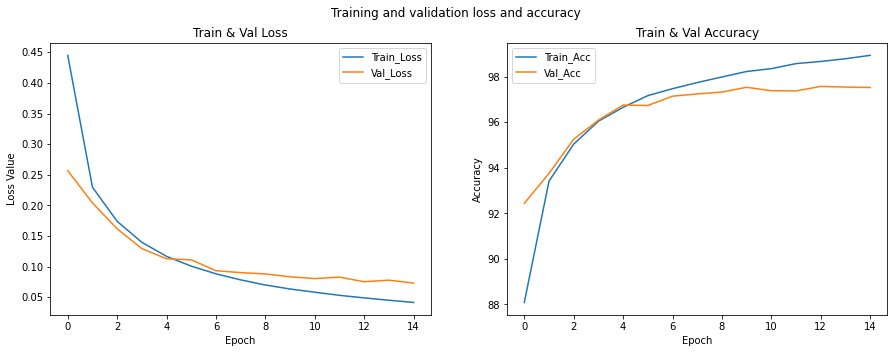

In [20]:
plot_L_A(train_losses_opt, val_losses_opt, train_accuracies_opt, val_accuracies_opt) 